In [1]:
# 1. Mengimpor library (alat ukur dan alat gambar) yang dibutuhkan
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Membaca file excel data gempa
df = pd.read_excel('3TIB_02_GempaIndonesiaTimur.xlsx')

# 3. Menampilkan 5 baris pertama untuk memastikan data sukses terbaca
print("=== 5 Baris Pertama Data ===")
display(df.head())

=== 5 Baris Pertama Data ===


,No,Date,Time (UTC),Latitude (deg),Longitude (deg),Depth (km),Magnitude (Mw)
0,1,2009-04-15,12:07:49,-8.388022,121.784996,11.886,3.97957
1,2,2009-04-15,12:39:07,1.209430,126.314896,8.350,3.90484
2,3,2009-04-15,16:46:55,-2.832804,120.628754,6.796,3.60592
3,4,2009-04-17,15:59:58,4.699714,125.548851,198.709,4.72932
4,5,2009-04-17,18:29:32,-0.509349,132.805573,46.750,5.23467


In [2]:
# Mengubah kolom 'Date' menjadi tipe data datetime (waktu)
df['Date'] = pd.to_datetime(df['Date'])

# Membuat kolom baru bernama 'Tahun' khusus untuk mengambil angka tahunnya saja
df['Tahun'] = df['Date'].dt.year

print("Prapemrosesan berhasil! Kolom 'Tahun' sudah ditambahkan.")

Prapemrosesan berhasil! Kolom 'Tahun' sudah ditambahkan.


In [3]:
print("=== STATISTIKA DESKRIPTIF MAGNITUDO ===")
print("Rata-rata (Mean)    :", df['Magnitude (Mw)'].mean())
print("Nilai Tengah (Median):", df['Magnitude (Mw)'].median())
print("Nilai Sering Muncul :", df['Magnitude (Mw)'].mode()[0])
print("Nilai Minimum       :", df['Magnitude (Mw)'].min())
print("Nilai Maksimum      :", df['Magnitude (Mw)'].max())
print("Rentang (Range)     :", df['Magnitude (Mw)'].max() - df['Magnitude (Mw)'].min())
print("Standar Deviasi     :", df['Magnitude (Mw)'].std())
print("Varians             :", df['Magnitude (Mw)'].var())

print("\n=== STATISTIKA DESKRIPTIF KEDALAMAN (DEPTH) ===")
print("Rata-rata (Mean)    :", df['Depth (km)'].mean())
print("Nilai Tengah (Median):", df['Depth (km)'].median())
print("Nilai Sering Muncul :", df['Depth (km)'].mode()[0])
print("Nilai Minimum       :", df['Depth (km)'].min())
print("Nilai Maksimum      :", df['Depth (km)'].max())
print("Rentang (Range)     :", df['Depth (km)'].max() - df['Depth (km)'].min())
print("Standar Deviasi     :", df['Depth (km)'].std())
print("Varians             :", df['Depth (km)'].var())

=== STATISTIKA DESKRIPTIF MAGNITUDO ===
Rata-rata (Mean)    : 4.2125699816214
Nilai Tengah (Median): 4.1229
Nilai Sering Muncul : 4.3250399999999996
Nilai Minimum       : 3.0
Nilai Maksimum      : 7.5
Rentang (Range)     : 4.5
Standar Deviasi     : 0.6072118243579543
Varians             : 0.36870619964011514

=== STATISTIKA DESKRIPTIF KEDALAMAN (DEPTH) ===
Rata-rata (Mean)    : 72.18473013273433
Nilai Tengah (Median): 32.023
Nilai Sering Muncul : 8.184
Nilai Minimum       : 3.02
Nilai Maksimum      : 714.613
Rentang (Range)     : 711.5930000000001
Standar Deviasi     : 98.35984812722558
Varians             : 9674.65972361088


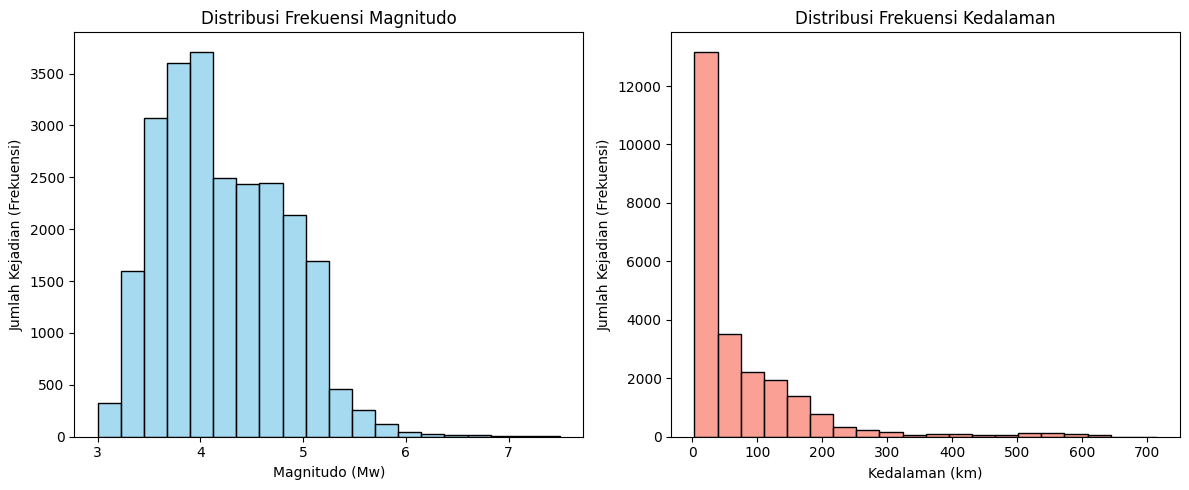

In [4]:
# Membuat 2 gambar berdampingan untuk Histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gambar 1: Histogram Magnitudo
sns.histplot(df['Magnitude (Mw)'], bins=20, color='skyblue', ax=axes[0])
axes[0].set_title('Distribusi Frekuensi Magnitudo')
axes[0].set_xlabel('Magnitudo (Mw)')
axes[0].set_ylabel('Jumlah Kejadian (Frekuensi)')

# Gambar 2: Histogram Kedalaman
sns.histplot(df['Depth (km)'], bins=20, color='salmon', ax=axes[1])
axes[1].set_title('Distribusi Frekuensi Kedalaman')
axes[1].set_xlabel('Kedalaman (km)')
axes[1].set_ylabel('Jumlah Kejadian (Frekuensi)')

# Menampilkan gambar dengan rapi
plt.tight_layout()
plt.show()

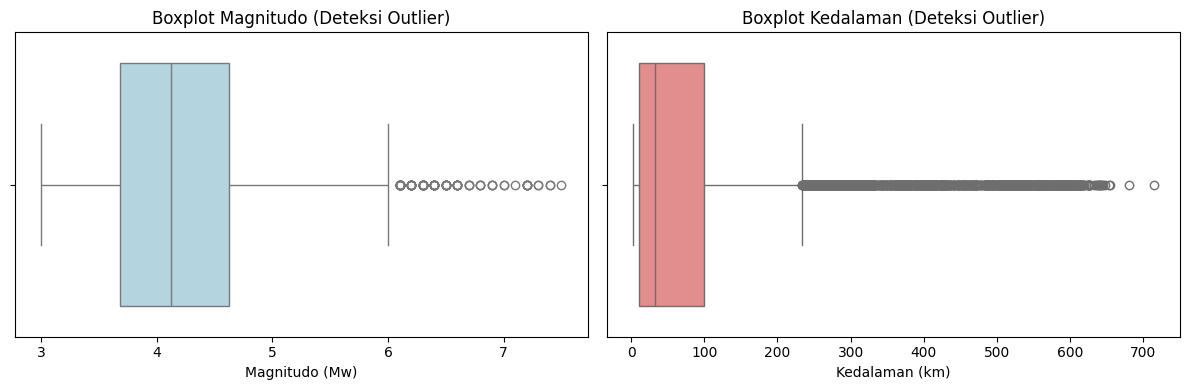

In [5]:
# Membuat 2 gambar berdampingan untuk Boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gambar 1: Boxplot Magnitudo
sns.boxplot(x=df['Magnitude (Mw)'], color='lightblue', ax=axes[0])
axes[0].set_title('Boxplot Magnitudo (Deteksi Outlier)')
axes[0].set_xlabel('Magnitudo (Mw)')

# Gambar 2: Boxplot Kedalaman
sns.boxplot(x=df['Depth (km)'], color='lightcoral', ax=axes[1])
axes[1].set_title('Boxplot Kedalaman (Deteksi Outlier)')
axes[1].set_xlabel('Kedalaman (km)')

plt.tight_layout()
plt.show()

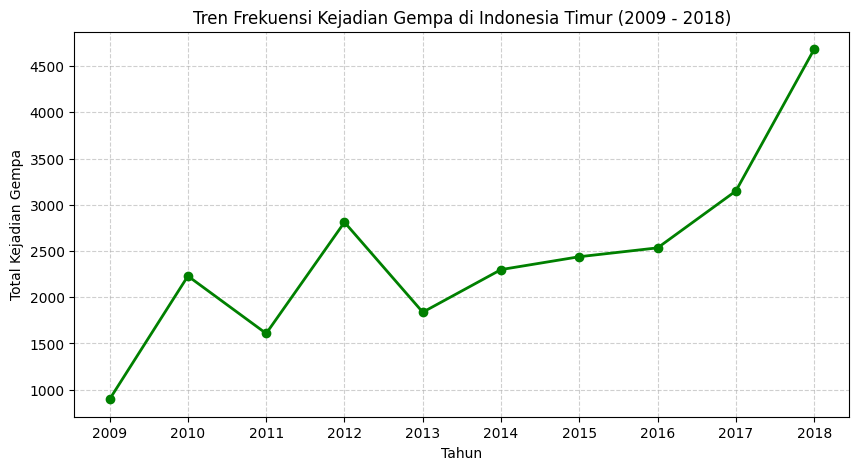

In [6]:
# Menghitung jumlah gempa berdasarkan tahun kejadian
jumlah_per_tahun = df['Tahun'].value_counts().sort_index()

# Membuat grafik garis (Time-Series Plot)
plt.figure(figsize=(10, 5))
plt.plot(jumlah_per_tahun.index, jumlah_per_tahun.values, marker='o', color='green', linewidth=2)

# Memberi judul dan label
plt.title('Tren Frekuensi Kejadian Gempa di Indonesia Timur (2009 - 2018)')
plt.xlabel('Tahun')
plt.ylabel('Total Kejadian Gempa')

# Menambahkan grid (garis bantu kotak-kotak) agar mudah dibaca
plt.grid(True, linestyle='--', alpha=0.6)

# Memastikan angka tahun di bawah (sumbu X) tidak berantakan
plt.xticks(jumlah_per_tahun.index)

plt.show()